# Notebook 50 -- S-B vs S-B3 classification, MATCHED (scenario-specific) warm start

Every scenario is simulated from the steady state of its own theta, the protocol the training banks were generated with. Only scenarios whose steady-state solve converges can be evaluated: W3, W11 and W16 are excluded for both models (no matched warm start exists at their theta).

Purpose: choose between S-B (5-D) and S-B3 (4-D) as the paper's System II on a like-for-like basis. Both posteriors are trained on full-uniform prior banks of 5000 matched-protocol simulations (same NSF 60x3, default z-scoring, seeds 0-4). They are evaluated on identical summary vectors (same scenarios, same replicates, same noise), classified with the same taxonomy (healthy/reactor/column/multi, threshold 0.90) on the first four parameters. Every seed is reported; no seed is selected by classification outcome.

Caveat: this is classification only. SBC calibration for each model is in its own training results; classification being equal does not imply equal calibration.

In [1]:

import pathlib, pickle, sys
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt

cwd = pathlib.Path.cwd().resolve()
ROOT = cwd if (cwd / 'src').exists() else cwd.parent
sys.path.insert(0, str(ROOT / 'src'))
from cstr_sbi.recycle.sb3 import (FAULT_UNITS_SB3, SB3_PARAM_NAMES, TRUE_UNIT_THRESH_SB3,
                                  fault_unit_sb3_truth, fault_unit_sb3_predict)

RESULTS, SBI_LOGS, FIGURES = ROOT / 'results', ROOT / 'sbi-logs', ROOT / 'figures'
PROTOCOL = 'matched'
TAG = '50_sb_vs_sb3_matched'
SEEDS = [0, 1, 2, 3, 4]
N_POST, PRED_THRESH = 200, TRUE_UNIT_THRESH_SB3
torch.manual_seed(2026)

# Scenario summaries simulated once by scripts/run_sb3_wideprior_training_and_classification.py.
# Both models are evaluated on exactly these x_o vectors (identical scenarios, replicates, noise).
scen_all = pickle.load(open(RESULTS / 'sb3_wideprior_scenario_summaries.pkl', 'rb'))
scen = scen_all[PROTOCOL]
print(PROTOCOL, 'protocol: ', len(scen), 'scenarios:', list(scen))


matched protocol:  9 scenarios: ['W1_healthy', 'W2_cat_mild', 'W4_cat_threshold', 'W5_jacket_mild', 'W6_jacket_severe', 'W7_col_eff_mild', 'W9_reb_fouling', 'W12_snowball_compound', 'W15_snowball_threshold']


## 1. Classify every scenario/replicate with both models

In [2]:

# Common taxonomy for the comparison: the S-B3 4-class taxonomy (healthy/reactor/column/multi),
# threshold 0.90 for both truth and prediction, applied to the first four parameters
# (alpha, beta_r, eta_col, xi_reb). The S-B posterior is 5-D; its z_A0 dimension is ignored here
# (feed-fault scenarios are not part of the shared scenario set).
def load_posterior(path):
    with open(path, 'rb') as f:
        return pickle.load(f)['posterior']

MODELS = {
    'S-B3 (4-D, full-uniform bank)': [SBI_LOGS / f'wu2003_posterior_sb3_wideprior_seed{k}.pkl' for k in SEEDS],
    'S-B  (5-D, full-uniform bank)': [SBI_LOGS / f'wu2003_posterior_sb_wideprior_baseline_seed{k}.pkl' for k in SEEDS],
}

def draw(post, s):
    with torch.no_grad():
        return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,
                           reject_outside_prior=False).detach().cpu().numpy()[:, :4]

def classify(samples):
    labels = [fault_unit_sb3_predict(r, thresh=PRED_THRESH) for r in samples]
    probs = {u: float(np.mean([l == u for l in labels])) for u in FAULT_UNITS_SB3}
    return max(probs, key=probs.__getitem__)

def metrics(preds, trues):
    cm = np.zeros((4, 4), int); c2i = {c: i for i, c in enumerate(FAULT_UNITS_SB3)}
    for t, p in zip(trues, preds):
        cm[c2i[t], c2i[p]] += 1
    f1 = {}
    for i, c in enumerate(FAULT_UNITS_SB3):
        tp = cm[i, i]; fp = cm[:, i].sum() - tp; fn = cm[i, :].sum() - tp
        pr = tp / (tp + fp) if tp + fp else 0.0; rc = tp / (tp + fn) if tp + fn else 0.0
        f1[c] = 2 * pr * rc / (pr + rc) if pr + rc else 0.0
    return cm, f1, float(np.mean(list(f1.values()))), float(np.trace(cm) / cm.sum())

seed_rows, scen_rows = [], []
for model, paths in MODELS.items():
    for seed, path in zip(SEEDS, paths):
        post = load_posterior(path)
        preds, trues = [], []
        for name, (th4, sums) in scen.items():
            tu = fault_unit_sb3_truth(th4); rp = []; pooled = []
            for s in sums:
                samp = draw(post, s); pooled.append(samp)
                p = classify(samp); rp.append(p); preds.append(p); trues.append(tu)
            pm = np.concatenate(pooled).mean(0)
            scen_rows.append(dict(model=model, seed=seed, scenario=name, true_unit=tu,
                                  acc=float(np.mean([p == tu for p in rp])),
                                  **{f'{n}_true': float(th4[k]) for k, n in enumerate(SB3_PARAM_NAMES)},
                                  **{f'{n}_mean': float(pm[k]) for k, n in enumerate(SB3_PARAM_NAMES)}))
        cm, f1, mf1, acc = metrics(preds, trues)
        seed_rows.append(dict(model=model, seed=seed, accuracy=acc, macro_f1=mf1,
                              **{f'f1_{c}': v for c, v in f1.items()}))
        print(f'{model} seed {seed}: acc={acc:.3f} macroF1={mf1:.3f}')

seed_df, scen_df = pd.DataFrame(seed_rows), pd.DataFrame(scen_rows)
seed_df.to_csv(RESULTS / f'{TAG}_per_seed.csv', index=False)
scen_df.to_csv(RESULTS / f'{TAG}_per_scenario.csv', index=False)


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 67.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 75.5% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 27.5% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp

/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 43.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 58.5% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 21.5% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp

/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 16.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 20.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 5.5% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 73.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 15.5% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 50.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp

/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 85.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 24.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 42.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp

/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 31.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 57.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,


... (36 outputs left out)

/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 99.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,


S-B  (5-D, full-uniform bank) seed 3: acc=0.911 macroF1=0.907


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_98734/1831382538.py:16: UserWarning: 79.5% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  return post.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False,


S-B  (5-D, full-uniform bank) seed 4: acc=0.922 macroF1=0.916


## 2. Seed-aggregated headline

In [3]:

# Headline: mean/min/max over the five training seeds (every seed reported, none selected).
agg = seed_df.groupby('model')[['accuracy', 'macro_f1']].agg(['mean', 'min', 'max']).round(3)
print('=== Seed-aggregated classification (', PROTOCOL, 'warm start,', len(scen), 'scenarios) ===')
print(agg.to_string())
print()
print(seed_df.round(3).to_string(index=False))


=== Seed-aggregated classification ( matched warm start, 9 scenarios) ===
                              accuracy               macro_f1              
                                  mean    min    max     mean    min    max
model                                                                      
S-B  (5-D, full-uniform bank)    0.927  0.900  0.974    0.922  0.898  0.968
S-B3 (4-D, full-uniform bank)    0.947  0.907  0.967    0.940  0.904  0.960

                        model  seed  accuracy  macro_f1  f1_healthy  f1_reactor  f1_column  f1_multi
S-B3 (4-D, full-uniform bank)     0     0.907     0.904         1.0       0.909        1.0     0.706
S-B3 (4-D, full-uniform bank)     1     0.959     0.952         1.0       0.962        1.0     0.845
S-B3 (4-D, full-uniform bank)     2     0.952     0.944         1.0       0.955        1.0     0.822
S-B3 (4-D, full-uniform bank)     3     0.967     0.960         1.0       0.969        1.0     0.870
S-B3 (4-D, full-uniform bank)     4     

## 3. Per-scenario comparison

model                             S-B  (5-D, full-uniform bank)  S-B3 (4-D, full-uniform bank)  diff (S-B3 minus S-B)
scenario               true_unit                                                                                     
W12_snowball_compound  multi                               1.00                           1.00                   0.00
W15_snowball_threshold reactor                             0.35                           0.52                  -0.17
W1_healthy             healthy                             1.00                           1.00                   0.00
W2_cat_mild            reactor                             1.00                           1.00                   0.00
W4_cat_threshold       reactor                             0.99                           1.00                  -0.01
W5_jacket_mild         reactor                             1.00                           1.00                   0.00
W6_jacket_severe       reactor                          

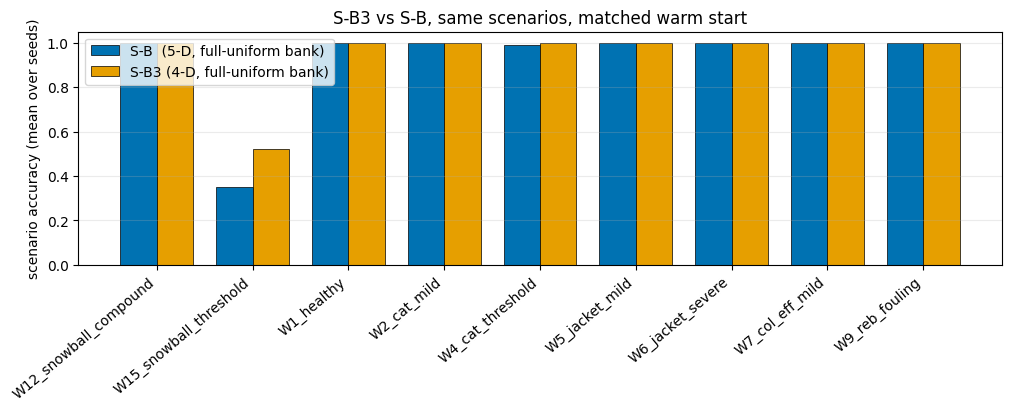

In [4]:

# Per-scenario accuracy, averaged over seeds, S-B3 vs S-B side by side.
pt = scen_df.pivot_table(index=['scenario', 'true_unit'], columns='model', values='acc', aggfunc='mean').round(2)
pt['diff (S-B3 minus S-B)'] = (pt.iloc[:, 0] - pt.iloc[:, 1]).round(2)
print(pt.to_string())
pt.to_csv(RESULTS / f'{TAG}_scenario_accuracy_table.csv')

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
idx = np.arange(len(pt)); w = 0.38
ax.bar(idx - w / 2, pt.iloc[:, 0], w, label=pt.columns[0], color='#0072B2', edgecolor='k', linewidth=0.5)
ax.bar(idx + w / 2, pt.iloc[:, 1], w, label=pt.columns[1], color='#E69F00', edgecolor='k', linewidth=0.5)
ax.set_xticks(idx); ax.set_xticklabels([i[0] for i in pt.index], rotation=40, ha='right')
ax.set_ylabel('scenario accuracy (mean over seeds)'); ax.set_ylim(0, 1.05); ax.legend()
ax.set_title(f'S-B3 vs S-B, same scenarios, {PROTOCOL} warm start'); ax.grid(True, axis='y', alpha=0.25)
fig.savefig(FIGURES / f'{TAG}_scenario_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()


## 4. Parameter recovery

In [5]:

# Posterior-mean parameter recovery on the shared scenarios (pooled over seeds and replicates).
rows = []
for model, g in scen_df.groupby('model'):
    for n in SB3_PARAM_NAMES:
        err = g[f'{n}_mean'] - g[f'{n}_true']
        rows.append(dict(model=model, parameter=n, bias=err.mean(), mae=err.abs().mean(), rmse=float(np.sqrt((err ** 2).mean()))))
print(pd.DataFrame(rows).round(3).to_string(index=False))


                        model parameter   bias   mae  rmse
S-B  (5-D, full-uniform bank)     alpha  0.002 0.003 0.005
S-B  (5-D, full-uniform bank)    beta_r  0.006 0.011 0.014
S-B  (5-D, full-uniform bank)   eta_col -0.010 0.017 0.026
S-B  (5-D, full-uniform bank)    xi_reb  0.006 0.007 0.009
S-B3 (4-D, full-uniform bank)     alpha  0.001 0.002 0.002
S-B3 (4-D, full-uniform bank)    beta_r  0.003 0.006 0.008
S-B3 (4-D, full-uniform bank)   eta_col -0.008 0.012 0.019
S-B3 (4-D, full-uniform bank)    xi_reb  0.003 0.005 0.006
